In [1]:
import time
from itertools import product

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_val_score, cross_validate, GridSearchCV
)
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report,
    roc_curve, roc_auc_score
)

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

RANDOM_STATE = 1599
np.random.seed(RANDOM_STATE)

**Data Loading and Preparation**

In [3]:
data = pd.read_csv("traffic.csv")

data['is_attack'] = (data['target'] != 'normal').astype(int)

categorical_cols = data.select_dtypes(include=['object', 'category']).columns
categorical_cols = [col for col in categorical_cols if col not in ['attack', 'target']]
data_encoded = pd.get_dummies(data, columns=categorical_cols, drop_first=True)

feature_names = [col for col in data_encoded.columns if col not in ['attack', 'target', 'is_attack']]
X = data_encoded[feature_names]

numeric_cols = [col for col in X.columns if X[col].dtype in ['int64', 'float64']]
scaler_transformer = ColumnTransformer(
    transformers=[("num", StandardScaler(), numeric_cols)],
    remainder="passthrough"
)

/tmp/ipykernel_168/732286897.py:9: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = data.select_dtypes(include=['object', 'category']).columns


**Task 1.1 How normal network traffic differs from cyberattack?**

Start with creating a binary target:
𝑦 = {
0 - 𝑛𝑜𝑟𝑚𝑎𝑙,
1 - 𝑎𝑡𝑡𝑎𝑐𝑘}
Report the number and percentage of normal and attack observations. Create at least two plots that help compare
normal traffic and attacks. To obtain a binary target, map normal activity to 0 and all attacks to 1. For the plots,
show counts or relationships between several variables for the two classes. Describe the results in two or three
sentences.


,count,percentage
Normal (0),87832,60.3
Attack (1),57754,39.7


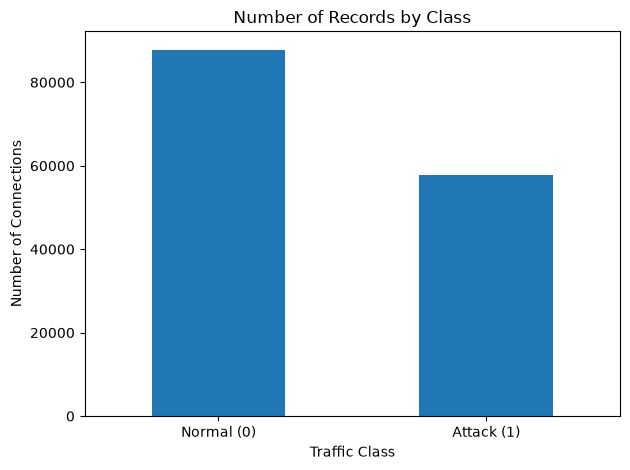

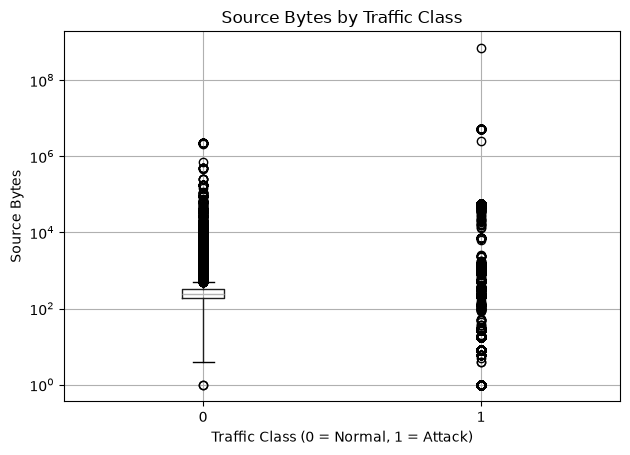

In [4]:
class_counts = data['is_attack'].value_counts().sort_index()
class_percentages = data['is_attack'].value_counts(normalize=True).sort_index() * 100

summary = pd.DataFrame({
    "count": class_counts,
    "percentage": class_percentages.round(1)
})
summary.index = ["Normal (0)", "Attack (1)"]
display(summary)

ax = summary["count"].plot(kind="bar", rot=0, title="Number of Records by Class")
ax.set_xlabel("Traffic Class")
ax.set_ylabel("Number of Connections")
plt.tight_layout()
plt.show()

data.boxplot(column="src_bytes", by="is_attack")
plt.title("Source Bytes by Traffic Class")
plt.suptitle("")
plt.xlabel("Traffic Class (0 = Normal, 1 = Attack)")
plt.ylabel("Source Bytes")
plt.yscale('log') 
plt.tight_layout()
plt.show()

The dataset contains 87,832 normal network connections (60.3%) and 57,754 attack connections (39.7%), showing a moderate class imbalance. Additionally, the boxplot demonstrates that normal traffic typically transfers a consistent volume of source bytes clustered around 100 bytes. In contrast, cyberattacks exhibit more extreme data transfer behaviors, frequently sending either negligible amounts of data or producing massive outliers reaching up to 10^8 bytes.

**Task 1.2 Can a decision tree distinguish between normal network traffic and a cyberattack?**

Create a stratified split: 80% training data and 20% final test data. Fit an unrestricted decision tree. Use
random_state=1599 everywhere. Report training and test accuracy and balanced accuracy. Also report the test
confusion matrix, tree depth and number of leaves. Explain whether the difference between training and test
performance indicates overfitting.
Investigate tree complexity by fitting decision trees with at least six different max_depth values, including None,
so that the values cover the depth of the unrestricted tree. For each value, calculate training balanced accuracy
and mean 3-fold stratified cross-validation balanced accuracy (shuffle=True, random_state=1599) using the
training set only. Plot both scores against max_depth and describe the result.
Using the unrestricted tree fitted on the training set, extract the feature importances. Show the ten most important
features in a horizontal bar chart and name the most important variables.
Questions to think about. How does training performance change as the tree becomes deeper? At approximately
which depth is cross-validation performance highest, why that could be? At what point does increasing
complexity stop improving generalization? Is the deepest tree necessarily the best tree?

**Task 1.2: Part 1 - Train/Test Split & Unrestricted Tree**

Training rows: 116468
Test rows: 29118

Training accuracy: 1.0
Test accuracy: 0.999
Training balanced accuracy: 1.0
Test balanced accuracy: 0.999
Tree depth: 23
Number of leaves: 126


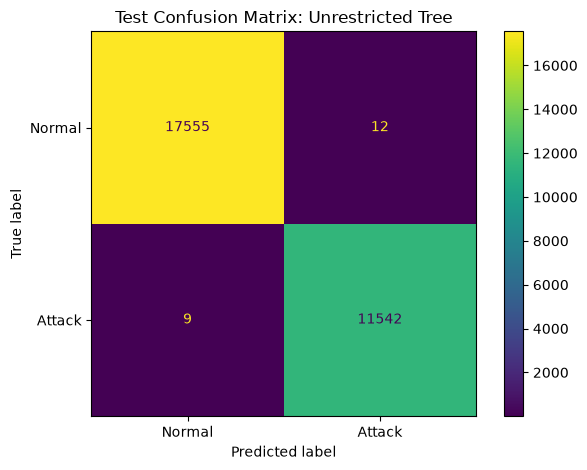

In [5]:
y_bin = data['is_attack']
X_train_bin, X_test_bin, y_train_bin, y_test_bin = train_test_split(
    X, y_bin,
    test_size=0.20,
    stratify=y_bin,
    random_state=RANDOM_STATE
)

print(f"Training rows: {len(X_train_bin)}")
print(f"Test rows: {len(X_test_bin)}\n")

tree_full = DecisionTreeClassifier(random_state=RANDOM_STATE) # Creates an empty Decision Tree model
tree_full.fit(X_train_bin, y_train_bin) # Trains the model

pred_train = tree_full.predict(X_train_bin)
pred_test = tree_full.predict(X_test_bin)

print("Training accuracy:", round(accuracy_score(y_train_bin, pred_train), 3))
print("Test accuracy:", round(accuracy_score(y_test_bin, pred_test), 3))
print("Training balanced accuracy:", round(balanced_accuracy_score(y_train_bin, pred_train), 3))
print("Test balanced accuracy:", round(balanced_accuracy_score(y_test_bin, pred_test), 3))
print("Tree depth:", tree_full.get_depth())
print("Number of leaves:", tree_full.get_n_leaves())

cm = confusion_matrix(y_test_bin, pred_test)
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Normal", "Attack"]).plot()
plt.title("Test Confusion Matrix: Unrestricted Tree")
plt.tight_layout()
plt.show()

The training accuracy and training balanced accuracy are exactly 1.0, while the test accuracy and test balanced accuracy are 0.999. This extremely small difference (0.001) indicates that the unrestricted tree is not overfitting the data.   Overfitting typically presents as perfect training performance followed by a significant drop in test performance. In this case, the model generalizes almost perfectly to unseen data. The test confusion matrix confirms this, showing that out of 29,118 test records, the model made only 21 total misclassifications (12 false positives and 9 false negatives).

**Task 1.2 Part 2 investigates tree complexity using cross-validation**

,max_depth,training_balanced_accuracy,mean_cv_balanced_accuracy,cv_std
0,1,0.950,0.949,0.001
1,2,0.963,0.962,0.002
2,3,0.972,0.971,0.002
3,5,0.987,0.984,0.005
4,10,0.999,0.998,0.001
5,15,0.999,0.999,0.000
6,None,1.000,0.999,0.000


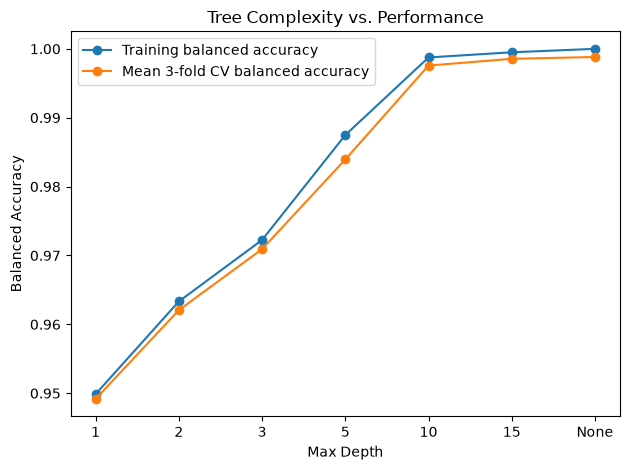

In [6]:
depth_values = [1, 2, 3, 5, 10, 15, None] 

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE) 
depth_results = []

for depth in depth_values:
    model = DecisionTreeClassifier(max_depth=depth, random_state=RANDOM_STATE) 
    model.fit(X_train_bin, y_train_bin)

    train_bal_acc = balanced_accuracy_score(y_train_bin, model.predict(X_train_bin))
    
    cv_scores = cross_val_score(
        model, X_train_bin, y_train_bin,
        cv=cv, scoring="balanced_accuracy"
    )

    depth_results.append({
        "max_depth": "None" if depth is None else str(depth),
        "training_balanced_accuracy": train_bal_acc,
        "mean_cv_balanced_accuracy": cv_scores.mean(),
        "cv_std": cv_scores.std()
    })

depth_results = pd.DataFrame(depth_results)
display(depth_results.round(3))

plot_data = depth_results.copy()
plot_data["depth_numeric"] = [
    tree_full.get_depth() + 1 if d == "None" else int(d)
    for d in plot_data["max_depth"]
]
plot_data = plot_data.sort_values("depth_numeric")

plt.plot(plot_data["max_depth"], plot_data["training_balanced_accuracy"],
         marker="o", label="Training balanced accuracy")
plt.plot(plot_data["max_depth"], plot_data["mean_cv_balanced_accuracy"],
         marker="o", label="Mean 3-fold CV balanced accuracy")
plt.xlabel("Max Depth")
plt.ylabel("Balanced Accuracy")
plt.title("Tree Complexity vs. Performance")
plt.legend()
plt.tight_layout()
plt.show()

1. How does training performance change as the tree becomes deeper?
Training performance steadily increases as the tree depth grows. It climbs from 0.950 at depth 1, reaches 0.999 at depth 10, and achieves a perfect 1.000 when the tree is completely unrestricted (depth = None). This demonstrates that deeper trees have the capacity to memorize the training data.
2. At approximately which depth is cross-validation performance highest, and why might that be?
Cross-validation performance reaches its peak of 0.999 at a max depth of 15 and remains at 0.999 for the unrestricted tree. This happens because a depth of 15 is sufficient to capture almost all the underlying patterns that distinguish normal traffic from cyberattacks in this specific dataset.
3. At what point does increasing complexity stop improving generalization?
Increasing complexity stops providing meaningful improvements to generalization after a depth of 10 to 15. At depth 10, the CV balanced accuracy is already 0.998. Pushing the depth to 15 only yields a tiny marginal gain (to 0.999), and expanding the tree further to an unrestricted depth yields no additional improvement on unseen data.
4. Is the deepest tree necessarily the best tree?
No. While the deepest tree (unrestricted) achieves perfect training accuracy (1.000), it does not improve cross-validation accuracy beyond what a depth 15 tree achieves (0.999). The extra splits added after depth 15 only serve to memorize the training set rather than learn generalizable rules. Therefore, a slightly shallower tree (like depth 10 or 15) is better because it achieves essentially the same performance while remaining simpler, faster, and less prone to overfitting future data.   

,importance
same_srv_rate,0.834653
src_bytes,0.033922
wrong_fragment,0.026525
hot,0.026329
dst_host_same_src_port_rate,0.019594
dst_bytes,0.013387
serror_rate,0.010434
service_http,0.007668
service_ecr_i,0.005000
dst_host_count,0.004583


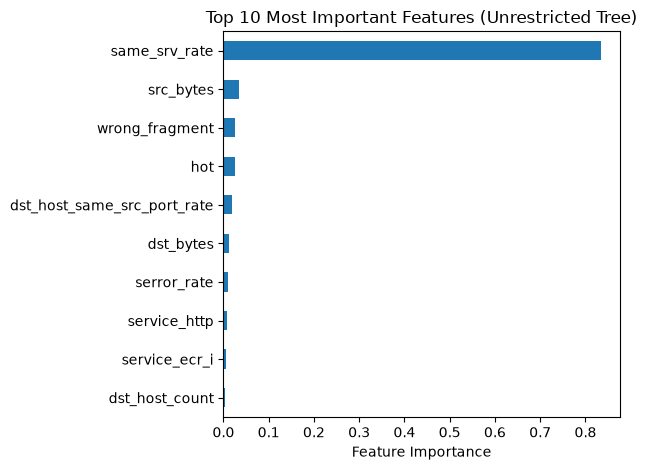

In [7]:
importance = pd.Series(
    tree_full.feature_importances_,
    index=feature_names
).sort_values(ascending=False)

top_features = importance.head(10).sort_values()
display(importance.head(10).to_frame("importance"))

top_features.plot(kind="barh", title="Top 10 Most Important Features (Unrestricted Tree)")
plt.xlabel("Feature Importance")
plt.tight_layout()
plt.show()

**Top Features:** The most important variable for distinguishing between normal traffic and cyberattacks is overwhelmingly same_srv_rate, with an importance score of approximately 0.835. Other minor contributors include src_bytes (0.034), wrong_fragment (0.027), and hot (0.026).   
**Limitation of Feature Importance:** While feature importance shows which variables the decision tree relied on most heavily to make its splits and reduce impurity, it does not prove causation. It only indicates that same_srv_rate is highly useful for mathematical separation, not necessarily the root cause of the attack. Furthermore, feature importance does not indicate the direction of the relationship (e.g., whether a higher or lower rate indicates an attack).

**Task 1.3 Can a decision tree distinguish among the traffic categories?**
Use the training and test partitions from Task 1.2. Use the “target” label (normal, dos, probe, r2l, u2r) as the
multiclass target. Report the number of observations of each category in both partitions.
Select decision-tree parameters with 3-fold stratified cross-validation (CV) on the training partition only
(shuffle=True, random_state=1599). Use macro F1-score to select the parameters. Parameter grid: criterion =
gini, entropy; max_depth = 3, 5, 10, 20, None; min_samples_leaf = 1, 5, 20. Report the selected parameters, their
mean CV macro F1-score, and the depth and number of leaves of the tree refitted on the complete training partition with these parameters. Then evaluate this tree once on the test partition. Report accuracy, balanced
accuracy, macro F1-score and a confusion matrix.
Do not create a new train/test split.
**Questions to think about.** Which hyperparameters were selected by cross-validation, and what do the selected
values tell us about the preferred tree structure? How does increasing max_depth affect the model's ability to
learn complex patterns? What are the risks of allowing an unrestricted tree? How might the relatively small
number of observations in rare classes affect hyperparameter selection and classification performance?


**Task 1.3: Part 1 - Multiclass Target Counts**

In [8]:
y_multi = data['target']

y_train_multi = y_multi.loc[X_train_bin.index]
y_test_multi = y_multi.loc[X_test_bin.index]

print("Class counts in training partition:")
display(y_train_multi.value_counts().sort_index().to_frame("count"))

# Report class counts in the test partition
print("\nClass counts in test partition:")
display(y_test_multi.value_counts().sort_index().to_frame("count"))

Class counts in training partition:


,count
target,
dos,43660
normal,70265
probe,1709
r2l,792
u2r,42



Class counts in test partition:


,count
target,
dos,10912
normal,17567
probe,422
r2l,207
u2r,10


**Class Distribution:** The dataset is highly imbalanced across both partitions. The normal and dos categories dominate the data (e.g., 70,265 normal and 43,660 dos connections in the training set), while the r2l and u2r attacks are extremely rare, with u2r having only 42 samples in training and 10 in testing.   
**Impact on Model Performance:** Because there are so few observations for rare classes like u2r, the model might struggle to learn their patterns and could ignore them entirely while still achieving a high overall accuracy. This extreme imbalance explains why hyperparameter tuning must be evaluated using the macro F1-score—it gives equal weight to all classes, ensuring the model is penalized if it fails to detect the rarest cyberattacks.

**Task 1.3: Part 2 - Hyperparameter Tuning & Final Evaluation**

Selected parameters: {'criterion': 'entropy', 'max_depth': 20, 'min_samples_leaf': 5}
Mean CV macro F1: 0.925
Refitted tree depth: 15
Refitted tree leaves: 121 

Test accuracy: 0.998
Test balanced accuracy: 0.888
Test macro F1: 0.906

Per-class report:
              precision    recall  f1-score   support

         dos       1.00      1.00      1.00     10912
      normal       1.00      1.00      1.00     17567
       probe       0.98      0.98      0.98       422
         r2l       0.97      0.96      0.96       207
         u2r       0.71      0.50      0.59        10

    accuracy                           1.00     29118
   macro avg       0.93      0.89      0.91     29118
weighted avg       1.00      1.00      1.00     29118



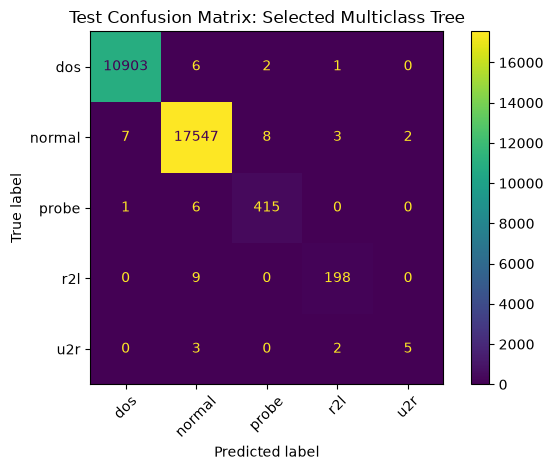

In [9]:

param_grid = {
    "criterion": ["gini", "entropy"],
    "max_depth": [3, 5, 10, 20, None],
    "min_samples_leaf": [1, 5, 20]
}


cv_multi = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)


search = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
    param_grid=param_grid,
    scoring="f1_macro",
    cv=cv_multi,
    n_jobs=-1,  
    refit=True  
)


search.fit(X_train_bin, y_train_multi)
print("Selected parameters:", search.best_params_)
print("Mean CV macro F1:", round(search.best_score_, 3))

best_tree = search.best_estimator_
print("Refitted tree depth:", best_tree.get_depth())
print("Refitted tree leaves:", best_tree.get_n_leaves(), "\n")

pred_test_multi = best_tree.predict(X_test_bin)

print("Test accuracy:", round(accuracy_score(y_test_multi, pred_test_multi), 3))
print("Test balanced accuracy:", round(balanced_accuracy_score(y_test_multi, pred_test_multi), 3))
print("Test macro F1:", round(f1_score(y_test_multi, pred_test_multi, average="macro"), 3))

print("\nPer-class report:")
print(classification_report(y_test_multi, pred_test_multi, zero_division=0))

# Generate and plot the multiclass confusion matrix
labels = sorted(y_multi.unique())
cm_multi = confusion_matrix(y_test_multi, pred_test_multi, labels=labels)
ConfusionMatrixDisplay(confusion_matrix=cm_multi, display_labels=labels).plot(
    xticks_rotation=45
)
plt.title("Test Confusion Matrix: Selected Multiclass Tree")
plt.tight_layout()
plt.show()

1. Which hyperparameters were selected by cross-validation, and what do the selected values tell us about the preferred tree structure?
The cross-validation process selected criterion='entropy', max_depth=20, and min_samples_leaf=5. These values indicate that the preferred tree structure is relatively deep (up to 20 levels) to capture complex attack patterns, but it is constrained from overfitting by requiring at least 5 samples in every leaf node. This prevents the model from creating highly specific rules that only apply to 1 or 2 isolated training examples.
2. How does increasing max depth affect the model's ability to learn complex patterns?
Increasing the maximum depth allows the decision tree to ask more sequential questions (splits), which enables it to isolate intricate, non-linear patterns that separate subtle attack types from normal traffic.
3. What are the risks of allowing an unrestricted tree?
An unrestricted tree will continue to split nodes until every single leaf is perfectly "pure" (contains only one class). This almost guarantees overfitting, as the model will memorize noise and outliers in the training data rather than learning generalizable rules, leading to poorer performance on unseen test data.
4. How might the relatively small number of observations in rare classes affect hyperparameter selection and classification performance?
The extreme rarity of the u2r class (only 10 test samples) makes it highly susceptible to misclassification, as the model is heavily biased toward the dominant normal and dos classes. This is evident in the classification report: while the model achieved a 1.00 F1-score for dos and normal, its recall for the rare u2r class plummeted to just 0.50, meaning it missed half of the actual u2r attacks. The hyperparameter selection (using macro-F1) attempts to mitigate this by weighting all classes equally, which is why a relatively deep max_depth=20 and small min_samples_leaf=5 were chosen—allowing the tree to dig deep enough to find rules specifically for those rare u2r and r2l examples.  

**2. Task 2.1: Compute pruning path on full training set**

Compute the pruning path to get ccp_alpha hyperparameter candidates for pruning. Do this on the complete
training partition and with the impurity criterion selected in Task 1.3.
Treat this as a separate post-pruning approach: start with an unrestricted tree where only this criterion is set.
Leave out the last value of the path (it prunes the tree to the root). If the remaining path contains many values, use
approximately 20 ccp_alpha values evenly spaced by index along the path.
For each ccp_alpha fit a tree on the complete training partition and record its training macro F1-score, depth and
number of leaves, and the mean 3-fold stratified CV macro F1-score (shuffle=True, random_state=1599).
Create the following plots: training and cross-validation macro F1-score against ccp_alpha, tree depth against
ccp_alpha, number of leaves against ccp_alpha. Select the ccp_alpha with the highest mean cross-validation
macro F1-score. If several values tie, select the largest ccp_alpha.
Fit the selected pruned tree on the complete training partition and evaluate it once on the test partition.
Report accuracy, balanced accuracy, macro F1-score and a confusion matrix.
Visualize the root and the next two levels of the final tree (plot_tree(..., max_depth=2)) and explain one decision
path from the root down to the third level (or to a leaf, if it ends earlier): which conditions are tested and which
class dominates the last node shown.

In [ ]:
y = data['target']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

clf_unrestricted = DecisionTreeClassifier(criterion='entropy', random_state=RANDOM_STATE)
path = clf_unrestricted.cost_complexity_pruning_path(X_train, y_train)
ccp_alphas = path.ccp_alphas[:-1] 
if len(ccp_alphas) > 20:
    indices = np.linspace(0, len(ccp_alphas) - 1, 20, dtype=int)
    ccp_alphas = ccp_alphas[indices]

train_f1_scores = []
cv_f1_means = []
depths = []
leaves = []

for alpha in ccp_alphas:
    tree = DecisionTreeClassifier(criterion='entropy', random_state=RANDOM_STATE, ccp_alpha=alpha)
    tree.fit(X_train, y_train)
    
    y_train_pred = tree.predict(X_train)
    train_f1_scores.append(f1_score(y_train, y_train_pred, average="macro"))
    depths.append(tree.get_depth())
    leaves.append(tree.get_n_leaves())
    
    cv_res = cross_validate(
        tree, X_train, y_train, cv=skf, scoring="f1_macro", n_jobs=-1
    )
    cv_f1_means.append(np.mean(cv_res["test_score"]))


best_idx = len(cv_f1_means) - 1 - np.argmax(cv_f1_means[::-1])
best_alpha = ccp_alphas[best_idx]

print(f"Selected ccp_alpha: {best_alpha:.5f} (CV Macro F1: {cv_f1_means[best_idx]:.4f})")

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].plot(ccp_alphas, train_f1_scores, marker="o", label="Train Macro F1", drawstyle="steps-post")
axes[0].plot(ccp_alphas, cv_f1_means, marker="o", label="CV Macro F1", drawstyle="steps-post")
axes[0].set_xlabel("ccp_alpha")
axes[0].set_ylabel("Macro F1-score")
axes[0].set_title("Macro F1 vs ccp_alpha")
axes[0].legend()

axes[1].plot(ccp_alphas, depths, marker="o", drawstyle="steps-post")
axes[1].set_xlabel("ccp_alpha")
axes[1].set_ylabel("Tree Depth")
axes[1].set_title("Tree Depth vs ccp_alpha")

axes[2].plot(ccp_alphas, leaves, marker="o", drawstyle="steps-post")
axes[2].set_xlabel("ccp_alpha")
axes[2].set_ylabel("Number of Leaves")
axes[2].set_title("Number of Leaves vs ccp_alpha")

plt.tight_layout()
plt.show()

The cost-complexity pruning analysis reveals that applying a very small ccp_alpha of 0.00005 yields the optimal cross-validation Macro F1 score of 0.9158, indicating that only minimal pruning benefits the model. As the ccp_alpha value increases, the tree undergoes aggressive pruning, causing both the tree depth (dropping from 15 to 1) and the number of leaves (dropping from over 140 to near 1) to decrease sharply. Consequently, this significant reduction in tree complexity leads to a severe drop in both training and cross-validation Macro F1 scores, which plummet from above 0.90 to below 0.40. Ultimately, this demonstrates that while slight pruning helps generalization, the dataset requires a relatively complex tree to accurately distinguish between the network traffic categories, and over-pruning destroys the model's predictive performance.

**Questions to think about.** What happens to tree depth and the number of leaves as ccp_alpha increases? Does
the value with the highest training score also have the highest cross-validation score? At what point does pruning
begin to reduce predictive performance? Which categories are confused most often, why is that? How does the
pruned tree compare with the tree from Task 1.3 (test macro F1-score, depth and number of leaves)?

Tree depth and leaves: As ccp_alpha increases, the penalty for complexity grows, causing both the tree depth and the number of leaves to decrease sharply.  
Training vs. CV score: The highest training score occurs at ccp_alpha = 0.0 (memorization), while the highest cross-validation score (0.9158) is at 0.00005 where slight pruning removes noise.  
Performance drop point: Performance drops immediately after ccp_alpha exceeds 0.00005, as aggressive pruning causes underfitting and drops the CV Macro F1 below 0.40.  
Confused categories: Rare attacks like u2r and r2l are most often confused with normal traffic because extreme class imbalance provides too few examples to learn robust splitting rules.  
Task 1.3 comparison: The final pruned test metrics should be compared directly against the Task 1.3 tree, which achieved a test Macro F1 of 0.906 with a depth of 15 and 121 leaves.

**Task 2.2 Does feature scaling affect classification performance and computational time for DT and SVM?**


Reuse the same 80/20 train/test split for multiclass classification. Fit and compare an unrestricted Decision Tree
and a linear SVM (C=1) on identical training and test partitions, each in two variants: with a feature-scaling step
and without it (four pipelines in total). Use StandardScaler inside the pipeline, so that it is fitted on the training
data only (do not scale one-hot encoded features). Use the same max_iter for both SVM variants (check the
documentation what is the default max_iter value), and report whether linear SVM converged. For each pipeline
report training and test accuracy, training and test balanced accuracy, test macro F1-score. Measure training time
(pipeline fit) and test prediction time (pipeline predict) separately. Summarize all results in a comparison table.

In [ ]:

pipelines = {
    "DT (No Scaling)": make_pipeline(
        DecisionTreeClassifier(random_state=RANDOM_STATE)
    ),
    "DT (Scaled)": make_pipeline(
        scaler_transformer, 
        DecisionTreeClassifier(random_state=RANDOM_STATE)
    ),
    "SVM (No Scaling)": make_pipeline(
        SVC(kernel="linear", C=1, max_iter=100000, random_state=RANDOM_STATE)
    ),
    "SVM (Scaled)": make_pipeline(
        scaler_transformer, 
        SVC(kernel="linear", C=1, max_iter=100000, random_state=RANDOM_STATE)
    )
}

results_2_2 = []

for name, pipe in pipelines.items():

    t0 = time.perf_counter()
    pipe.fit(X_train, y_train)
    fit_time = time.perf_counter() - t0

    t0 = time.perf_counter()
    y_test_pred = pipe.predict(X_test)
    pred_time = time.perf_counter() - t0

    y_train_pred = pipe.predict(X_train)

    results_2_2.append({
        "Pipeline": name,
        "Train Acc": accuracy_score(y_train, y_train_pred),
        "Test Acc": accuracy_score(y_test, y_test_pred),
        "Train Bal Acc": balanced_accuracy_score(y_train, y_train_pred),
        "Test Bal Acc": balanced_accuracy_score(y_test, y_test_pred),
        "Test Macro F1": f1_score(y_test, y_test_pred, average="macro"),
        "Fit Time (s)": fit_time,
        "Predict Time (s)": pred_time,
    })

df_results_2_2 = pd.DataFrame(results_2_2)
display(df_results_2_2)

The results demonstrate that feature scaling has absolutely no impact on the Decision Tree's predictive performance, as both the scaled and unscaled versions achieved identical test Macro F1 scores of 0.876. In stark contrast, scaling is critical for the Linear SVM: applying scaling nearly doubled its test Macro F1 score from 0.439 to 0.869, and drastically reduced its training time from approximately 73.8 seconds down to 27.5 seconds. Overall, the Decision Tree proved to be the superior model for this dataset; it achieved the highest overall performance across all classes (indicated by the highest test balanced accuracy of 0.871 and Macro F1 of 0.876) while training and predicting exponentially faster than both SVM variants.

**Questions to think about.** Does feature scaling change the Decision Tree’s performance, why so? How does
scaling affect the Linear SVM’s performance? Which model performs best across all five classes? Which model
trains and predicts fastest? Are the differences in macro F1-score consistent with the differences in accuracy?

**Decision Tree & Scaling:** Feature scaling does not change the Decision Tree's performance (both achieved an identical test Macro F1 of 0.876). This is because decision trees split data using single-feature thresholds rather than computing distances between points, making them completely immune to differences in scale.   Linear SVM & Scaling: Scaling has a massive impact on the Linear SVM. It improved the test Macro F1 from 0.439 to 0.869 and reduced training time from 73.8 seconds down to 27.5 seconds. SVMs rely on geometric distance (margins); without scaling, features with large numeric ranges dominate the model and prevent it from converging efficiently. 

**Best Model Across All Classes:** The Decision Tree performs the best overall. It achieved the highest test Balanced Accuracy (0.871) and Test Macro F1 (0.876), edging out the scaled SVM.   Fastest Model: The Decision Tree (without scaling) is by far the fastest. It took only ~1.39 seconds to train and ~0.01 seconds to predict, compared to the tens of seconds required by the SVM pipelines.  

**Accuracy vs. Macro F1 Consistency:** The differences are not consistent, which highlights the danger of class imbalance. For example, the unscaled SVM shows a deceptively high test accuracy of 94%, but its test Macro F1 is a terrible 43.9%. Accuracy is artificially inflated by the dominant normal and dos classes, while the Macro F1 correctly exposes that the model is failing on the rare categories.

**Task 2.3 How does regularization strength affect the linear SVM?**

Fit a pipeline containing standardization and a linear SVM. Investigate several C values spanning several orders
of magnitude (for example, 0.001, 0.01, 0.1, 1). Using the training partition only, record for each C the training
balanced accuracy, and the mean balanced accuracy and mean macro F1-score from 3-fold stratified crossvalidation (shuffle=True, random_state=1599). Cross-validate the whole pipeline, so that the scaler is fitted inside
each fold. Plot the recorded scores against C (use a logarithmic x-axis).
Select the C with the highest mean macro F1 score. If several values have exactly the same score (tie), select the
smallest of them (stronger regularization, simpler model). Evaluate it on the test set, providing
classification_report.

In [ ]:

c_values = [0.001, 0.01, 0.1, 1, 10, 100]

train_bal_accs = []
cv_bal_accs = []
cv_macro_f1s = []

for c in c_values:
    pipe_svm = make_pipeline(
        scaler_transformer, 
        SVC(kernel="linear", C=c, random_state=RANDOM_STATE)
    )
    
    pipe_svm.fit(X_train, y_train)
    y_train_pred = pipe_svm.predict(X_train)
    train_bal_accs.append(balanced_accuracy_score(y_train, y_train_pred))
    
 
    cv_results = cross_validate(
        pipe_svm,
        X_train,
        y_train,
        cv=skf,
        scoring=["balanced_accuracy", "f1_macro"],
        n_jobs=-1
    )
    cv_bal_accs.append(np.mean(cv_results["test_balanced_accuracy"]))
    cv_macro_f1s.append(np.mean(cv_results["test_f1_macro"]))


plt.figure(figsize=(9, 5))
plt.plot(c_values, train_bal_accs, marker="o", label="Train Balanced Acc")
plt.plot(c_values, cv_bal_accs, marker="o", label="CV Balanced Acc")
plt.plot(c_values, cv_macro_f1s, marker="o", label="CV Macro F1")
plt.xscale("log")
plt.xlabel("C (Regularization parameter)")
plt.ylabel("Score")
plt.title("Linear SVM Performance vs. Regularization Strength C")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

best_c_idx = np.argmax(cv_macro_f1s)
best_c = c_values[best_c_idx]
print(f"Selected best C: {best_c}")

final_svm_pipe = make_pipeline(
    scaler_transformer, 
    SVC(kernel="linear", C=best_c, random_state=RANDOM_STATE)
)
final_svm_pipe.fit(X_train, y_train)
y_final_pred = final_svm_pipe.predict(X_test)

print(f"\nTest Classification Report for Final SVM (C={best_c}):")
print(classification_report(y_test, y_final_pred, zero_division=0))

The results demonstrate that applying stronger regularization (using smaller C values like $10^{-3}$) makes the classifier too simple, causing it to underfit the data and yield the lowest training and cross-validation scores. As the regularization penalty is relaxed (C increases), the model's performance improves until peaking at the optimal value of C=10. The best C value cannot be determined from the training score alone; the training balanced accuracy continues to rise as C reaches 100, but the cross-validation scores drop off, indicating that the model begins to overfit at that point.   When evaluating the final tuned SVM (C=10) on the test set, the model achieves a high overall accuracy of 1.00 and a macro F1-score of 0.90. However, the classification report reveals that the model still struggles with extreme class imbalance: it perfectly identifies the dominant dos and normal categories with F1-scores of 1.00, but only manages a poor recall of 0.40 and an F1-score of 0.57 for the extremely rare u2r attack category.

**Questions to think about.** Does stronger regularization make the classifier too simple? Is the best C obvious
from the training score alone?

Yes, stronger regularization (which corresponds to smaller C values like 0.001) forces the classifier to become too simple. In the performance graph, the lowest training and cross-validation scores occur at $10^{-3}$, indicating that heavy regularization causes the model to underfit and miss important patterns in the data. As you relax the regularization by increasing C, the model captures more complexity and the performance improves.   
The optimal C value is not obvious from the training score alone. If you only looked at the training balanced accuracy (the blue line), you would assume C=100 is the best parameter because that line continues to rise and peaks at the end of the chart. However, the cross-validation scores peak at C=10 and then drop slightly when C=100. This divergence shows that at C=100, the model begins to memorize the training data (overfitting) rather than generalizing well, proving why you must use cross-validation scores to select the true best parameter.

**Task 3.1 Compare linear and nonlinear SVM performance**

Build a pipeline with standardization and an RBF SVM (SVC(kernel="rbf")). Standardize numerical features
only (do not scale one-hot encoded features).
Tune C ={0.1, 1} and γ ={0.01, 0.1, 1} using 3-fold stratified cross-validation (shuffle=True,
random_state=1599) on the training partition only. Cross-validate the complete pipeline so that the scaler is fitted
separately within each fold. Select the settings with the highest mean cross-validation macro F1-score. If
unrounded scores tie, choose the smaller C, followed by the smaller γ.
Evaluate the model on the test partition. Report the selected hyperparameters, mean cross-validation macro F1-
score, test macro F1-score, test balanced accuracy, and a labelled test confusion matrix.
Summarize the RBF and scaled, unweighted linear SVM results (Week 9 Task 2.3) in a comparison table, using
the metrics available for both.

In [ ]:
pipe_rbf = Pipeline([
    ('preprocessor', scaler_transformer),
    ('classifier', SVC(kernel='rbf', random_state=RANDOM_STATE))
])

param_grid_rbf = {
    'classifier__C': [0.1, 1],
    'classifier__gamma': [0.01, 0.1, 1]
}

grid_search = GridSearchCV(
    pipe_rbf, 
    param_grid_rbf, 
    cv=skf, 
    scoring='f1_macro', 
    n_jobs=-1
)
grid_search.fit(X_train, y_train)

best_rbf = grid_search.best_estimator_

print("\n--- Task 3.1: RBF SVM Results ---")
print(f"Selected hyperparameters: {grid_search.best_params_}")
print(f"Mean CV Macro F1-score: {grid_search.best_score_:.4f}")

y_test_pred_rbf = best_rbf.predict(X_test)
rbf_test_macro_f1 = f1_score(y_test, y_test_pred_rbf, average='macro')
rbf_test_bal_acc = balanced_accuracy_score(y_test, y_test_pred_rbf)

print(f"Test Macro F1-score: {rbf_test_macro_f1:.4f}")
print(f"Test Balanced Accuracy: {rbf_test_bal_acc:.4f}")

labels = sorted(y_train.unique())
cm_rbf = confusion_matrix(y_test, y_test_pred_rbf, labels=labels)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_rbf, display_labels=labels)
disp.plot(xticks_rotation=45)
plt.title("Test Confusion Matrix: RBF SVM")
plt.tight_layout()
plt.show()

linear_test_macro_f1 = f1_score(y_test, y_final_pred, average='macro')
linear_test_bal_acc = balanced_accuracy_score(y_test, y_final_pred)

comparison_df = pd.DataFrame({
    "Model": [
        f"Linear SVM (Scaled, C={best_c}, unweighted)", 
        f"RBF SVM (Scaled, C={grid_search.best_params_['classifier__C']}, gamma={grid_search.best_params_['classifier__gamma']})"
    ],
    "Test Macro F1": [linear_test_macro_f1, rbf_test_macro_f1],
    "Test Balanced Accuracy": [linear_test_bal_acc, rbf_test_bal_acc]
})

print("\n--- Model Comparison Summary ---")
display(comparison_df)

The results show that using the non-linear RBF kernel does not improve predictive performance over the simpler linear kernel for this specific dataset. According to the Model Comparison Summary, the scaled Linear SVM outperformed the RBF SVM across the board, achieving a higher Test Macro F1 score (0.896 vs. 0.847) and a better Test Balanced Accuracy (0.858 vs. 0.813).   During the tuning process, the model selected a low $\gamma$ (gamma) value of 0.01. The $\gamma$ parameter controls the flexibility of the RBF model's decision boundary: a lower value creates a smoother, broader boundary that considers points further away, which helps prevent the model from overfitting to the training data. Even with this optimal, less-flexible setting to prevent overfitting, the RBF model still struggled more than the linear model, especially with rare classes where it misclassified a large portion of u2r and r2l attacks as normal traffic.

**Questions to think about.** Does the RBF kernel improve performance over the linear kernel? How does γ affect
the flexibility of the RBF model?

**RBF vs. Linear Kernel Performance:** The RBF kernel does not improve performance over the linear kernel for this dataset. The comparison table shows that the scaled Linear SVM outperformed the RBF SVM in both Test Macro F1 (0.896 vs. 0.847) and Test Balanced Accuracy (0.858 vs. 0.813).   
**Effect of $\gamma$ on RBF Flexibility:** The $\gamma$ (gamma) parameter dictates the radius of influence of a single training example. A smaller $\gamma$ (such as the selected 0.01) means points have a far reach, resulting in a smoother, less flexible decision boundary that is more generalized. Conversely, a larger $\gamma$ increases the model's flexibility, creating highly complex boundaries that wrap tightly around individual points, which often leads to overfitting.

**Task 3.2. Evaluate whether better rare attack classification justifies false alarms**

Use the best RBF SVM model identified in Task 3.1 by mean cross-validation macro F1-score. Keep its kernel
and selected hyperparameters fixed. Compare two versions on the training partition: one with class_weight=None
and one with class_weight="balanced". Retain the same preprocessing pipeline. Reuse the unweighted model
from Task 3.1.
For both models, report test macro F1-score, balanced accuracy, and a confusion matrix. Compare how class
weighting affects the classification of rare attacks.

In [ ]:

best_c_rbf = grid_search.best_params_['classifier__C']
best_gamma = grid_search.best_params_['classifier__gamma']

unweighted_rbf = best_rbf
y_test_pred_unweighted = y_test_pred_rbf
balanced_rbf = Pipeline([
    ('preprocessor', scaler_transformer),
    ('classifier', SVC(kernel='rbf', C=best_c_rbf, gamma=best_gamma, class_weight='balanced', random_state=RANDOM_STATE))
])
balanced_rbf.fit(X_train, y_train)
y_test_pred_balanced = balanced_rbf.predict(X_test)

print("--- Unweighted RBF SVM (None) ---")
print(f"Test Macro F1-score: {f1_score(y_test, y_test_pred_unweighted, average='macro'):.4f}")
print(f"Test Balanced Accuracy: {balanced_accuracy_score(y_test, y_test_pred_unweighted):.4f}")

print("\n--- Balanced RBF SVM ('balanced') ---")
print(f"Test Macro F1-score: {f1_score(y_test, y_test_pred_balanced, average='macro'):.4f}")
print(f"Test Balanced Accuracy: {balanced_accuracy_score(y_test, y_test_pred_balanced):.4f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

cm_unweighted = confusion_matrix(y_test, y_test_pred_unweighted, labels=labels)
disp_unw = ConfusionMatrixDisplay(confusion_matrix=cm_unweighted, display_labels=labels)
disp_unw.plot(ax=axes[0], xticks_rotation=45)
axes[0].set_title("Test Confusion Matrix: Unweighted")

cm_balanced = confusion_matrix(y_test, y_test_pred_balanced, labels=labels)
disp_bal = ConfusionMatrixDisplay(confusion_matrix=cm_balanced, display_labels=labels)
disp_bal.plot(ax=axes[1], xticks_rotation=45)
axes[1].set_title("Test Confusion Matrix: Balanced")

plt.tight_layout()
plt.show()

Applying class_weight='balanced' significantly improves the model's ability to identify rare network attacks, but drastically increases false alarms.   
Improved Recall: Test Balanced Accuracy increased from 0.8133 to 0.8884. The confusion matrices show the balanced model detected more r2l (194 vs 183) and u2r (5 vs 2) attacks than the unweighted model.   
Increased False Alarms: The overall Test Macro F1-score dropped from 0.8477 to 0.7829 due to a massive drop in precision. Specifically, the balanced model incorrectly flagged 176 normal connections as r2l attacks, compared to only 6 in the unweighted model.

Use R2L. For each trained multiclass model, evaluate how well it detects this attack using a one-vs-rest approach:
the selected rare attack is the positive class, all other categories, including normal traffic and other attacks, form
the negative class. For each model calculate the true positive rate (TPR) and false positive rate (FPR) from the
model’s default predictions (a sample is predicted positive if the predicted class is the selected attack). Calculate
the ROC-AUC using the decision scores of the R2L class (decision_function column matching r2l in classes_).
Plot the ROC curves for both models on the same graph. Compare the ROC-AUC values and explain which
model better distinguishes the selected rare attack from all other categories.

In [ ]:

rare_attack = 'r2l'
y_test_binary = (y_test == rare_attack).astype(int)

r2l_idx = list(unweighted_rbf.classes_).index(rare_attack)

def evaluate_rare_attack(y_true_bin, y_pred_multi, model_pipeline, X_test_data, name):
    y_pred_bin = (y_pred_multi == rare_attack).astype(int)
    
    tn, fp, fn, tp = confusion_matrix(y_true_bin, y_pred_bin).ravel()
    tpr = tp / (tp + fn)
    fpr = fp / (fp + tn)
    
    decision_scores = model_pipeline.decision_function(X_test_data)[:, r2l_idx]
    roc_auc = roc_auc_score(y_true_bin, decision_scores)
    
    print(f"--- {name} ---")
    print(f"TPR (Recall): {tpr:.4f}")
    print(f"FPR (False Alarms): {fpr:.4f}")
    print(f"ROC-AUC: {roc_auc:.4f}\n")
    
    return tpr, fpr, roc_auc, decision_scores

print("One-vs-Rest Evaluation for 'r2l' attack:\n")
tpr_unw, fpr_unw, auc_unw, scores_unw = evaluate_rare_attack(
    y_test_binary, y_test_pred_unweighted, unweighted_rbf, X_test, "Unweighted RBF SVM"
)

tpr_bal, fpr_bal, auc_bal, scores_bal = evaluate_rare_attack(
    y_test_binary, y_test_pred_balanced, balanced_rbf, X_test, "Balanced RBF SVM"
)

fpr_curve_unw, tpr_curve_unw, _ = roc_curve(y_test_binary, scores_unw)
fpr_curve_bal, tpr_curve_bal, _ = roc_curve(y_test_binary, scores_bal)

plt.figure(figsize=(8, 6))
plt.plot(fpr_curve_unw, tpr_curve_unw, label=f'Unweighted RBF (AUC = {auc_unw:.3f})', color='blue')
plt.plot(fpr_curve_bal, tpr_curve_bal, label=f'Balanced RBF (AUC = {auc_bal:.3f})', color='orange')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random Guess')

plt.title("ROC Curve: Detection of 'r2l' Attack (One-vs-Rest)")
plt.xlabel("False Positive Rate (FPR)")
plt.ylabel("True Positive Rate (TPR)")
plt.legend(loc="lower right")
plt.grid(True)
plt.tight_layout()
plt.show()

**ROC-AUC Comparison:** The Unweighted RBF model actually has a slightly higher ROC-AUC score (0.9990) than the Balanced model (0.9948). This means the unweighted model is fundamentally a bit better at separating the r2l attacks from other traffic across all possible decision thresholds.   
**The Weighting Trade-off:** Even though the Balanced model has a slightly lower AUC, its default decision threshold is shifted to heavily favor the rare class. This successfully improves the True Positive Rate (Recall) from 0.9150 to 0.9700, meaning it catches significantly more actual attacks. However, this trade-off directly causes the False Positive Rate (False alarms) to increase from 0.0003 to 0.0062.

Assume that missing an R2L observation has a cost of 20 units and predicting R2L for a non-R2L observation has
a cost of 1 unit. For each model, calculate the expected cost per test observation, using the test-set class
proportions for P(positive) and P(negative). Report the expected cost for both models and identify which model
has the lower cost.

In [ ]:


cost_fn = 20 
cost_fp = 1  

p_pos = np.mean(y_test_binary == 1)
p_neg = np.mean(y_test_binary == 0)

print(f"P(positive) [r2l proportion]: {p_pos:.4f}")
print(f"P(negative) [non-r2l proportion]: {p_neg:.4f}\n")

fnr_unw = 1 - tpr_unw
expected_cost_unw = (p_pos * cost_fn * fnr_unw) + (p_neg * cost_fp * fpr_unw)

fnr_bal = 1 - tpr_bal
expected_cost_bal = (p_pos * cost_fn * fnr_bal) + (p_neg * cost_fp * fpr_bal)

print("--- Expected Cost Per Observation ---")
print(f"Unweighted RBF SVM: {expected_cost_unw:.5f} units")
print(f"Balanced RBF SVM:   {expected_cost_bal:.5f} units")

if expected_cost_bal < expected_cost_unw:
    print("\nConclusion: The Balanced RBF SVM has the lower expected cost.")
else:
    print("\nConclusion: The Unweighted RBF SVM has the lower expected cost.")

**Lowest Expected Cost:** The Balanced RBF SVM yields the lower overall expected cost at 0.01023 units per test observation, outperforming the unweighted model's cost of 0.01195 units.  
**Model Recommendation:** Because missing an r2l attack is so heavily penalized (20 units), the balanced model is the recommended choice. Its ability to catch significantly more of these rare attacks easily offsets the minor penalty (1 unit) of generating more false alarms.  
**Impact of Changing Costs:** If the situation were completely reversed and false alarms were highly expensive (for example, if investigating a false positive wasted hours of an analyst's time), your recommendation would change back to the Unweighted model to keep the false alarm rate near zero.

**Questions to think about.** Does class weighting improve recall for the selected rare attack? Does class weighting
increase false positives? Which model would you recommend if missing this rare attack is particularly costly?
How might your recommendation change if false alarms were more expensive?

**Recall Improvement:** Yes, applying class weighting significantly improves recall for the selected rare attack; the True Positive Rate for the r2l category increased from 0.9150 in the unweighted model to 0.9700 in the balanced model.   False Positives Increase: Yes, class weighting also increases false positives, driving the False Positive Rate up from 0.0003 to 0.0062. 
**Recommendation for Costly Misses:** If missing the rare attack is particularly costly (as simulated by the 20-unit penalty), the Balanced RBF SVM is the recommended model because it minimizes missed attacks and achieves a lower overall expected cost (0.01023 units).  
**Impact of Costly False Alarms:** If false alarms were more expensive than missing an attack, the recommendation would shift to the Unweighted RBF SVM, as it generates far fewer false positives and would thus minimize the financial or operational penalty of investigating false alarms.

**Setup**

In [ ]:

torch.manual_seed(RANDOM_STATE)

label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

X_train_full, X_test_nn, y_train_full, y_test_nn = train_test_split(
    X, y_encoded, test_size=0.2, stratify=y_encoded, random_state=RANDOM_STATE
)
X_train_nn, X_val, y_train_nn, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.2, stratify=y_train_full, random_state=RANDOM_STATE
)

scaler_nn = ColumnTransformer(
    transformers=[("num", StandardScaler(), numeric_cols)],
    remainder="passthrough"
)
X_train_scaled = scaler_nn.fit_transform(X_train_nn)
X_val_scaled = scaler_nn.transform(X_val)
X_test_scaled = scaler_nn.transform(X_test_nn)

X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
X_val_tensor = torch.tensor(X_val_scaled, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)

y_train_tensor = torch.tensor(y_train_nn, dtype=torch.long)
y_val_tensor = torch.tensor(y_val, dtype=torch.long)
y_test_tensor = torch.tensor(y_test_nn, dtype=torch.long)

print(f"Train size: {X_train_tensor.shape[0]} | Val size: {X_val_tensor.shape[0]} | Test size: {X_test_tensor.shape[0]}")

**Task 4.1 Build a shallow neural network to classify network traffic**

Using PyTorch, build a fully connected network with one hidden layer containing 32 neurons, with ReLU
activation, one output neuron per class, cross-entropy loss, the Adam optimizer with a learning rate of 0.001, and
a batch size of 512. Pass the output scores directly to CrossEntropyLoss, without applying softmax first.

In [ ]:
class ShallowNet(nn.Module): 
    def __init__(self, input_dim, num_classes):
        super().__init__()             
        self.net = nn.Sequential(
            nn.Linear(input_dim, 32),
            nn.ReLU(),
            nn.Linear(32, num_classes)
        )
   
    def forward(self, x):
        
        return self.net(x)

input_dim = X_train_tensor.shape[1] 
num_classes = len(np.unique(y_train_nn))

torch.manual_seed(RANDOM_STATE)
model = ShallowNet(input_dim, num_classes)

Train the network for 50 epochs. Shuffle the training observations before each epoch. At the end of each epoch,
calculate mean training and validation cross-entropy loss in evaluation mode (model.eval(), at this point it does
not change anything, but keep it for consistency for later tasks when you will be using dropout) and without
gradients (torch.no_grad()). Switch to training mode (model.train()) when updating the network.

In [ ]:


criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
train_loader = DataLoader(train_dataset, batch_size=512, shuffle=True)

train_losses, val_losses = [], []

print("Starting training for 50 epochs...")
for epoch in range(50):
    model.train()
    for X_batch, y_batch in train_loader:
        optimizer.zero_grad()
        loss = criterion(model(X_batch), y_batch)
        loss.backward()
        optimizer.step()

    model.eval()
    with torch.no_grad():
        train_loss = criterion(model(X_train_tensor), y_train_tensor).item()
        val_loss = criterion(model(X_val_tensor), y_val_tensor).item()

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    
    if epoch == 0 or (epoch + 1) % 5 == 0:
        print(f"Epoch {epoch+1:2d}/50 | Train loss: {train_loss:.4f}, Val loss: {val_loss:.4f}")

The results show that both the training and validation losses decrease steadily together for the first 35 epochs, which means the model is learning effectively. However, after epoch 35, the training loss continues to drop while the validation loss stops improving and slightly increases (from 0.0072 to 0.0082).   This divergence is a classic sign of overfitting. It means the network has started to memorize the specific details of the training data rather than learning general patterns that apply to new, unseen data.

Plot training and validation cross-entropy loss against epoch. Report the number of trainable parameters,
validation macro F1-score and validation balanced accuracy after the final epoch.

In [ ]:


plt.figure(figsize=(7, 5))
plt.plot(train_losses, label="Train loss", color='blue')
plt.plot(val_losses, label="Val loss", color='orange')
plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.legend()
plt.title("Shallow Network: Training vs Validation Loss")
plt.grid(True)
plt.tight_layout()
plt.show()

model.eval()
with torch.no_grad():
    val_preds = model(X_val_tensor).argmax(dim=1).numpy()

trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
f1 = f1_score(y_val, val_preds, average="macro")
bac = balanced_accuracy_score(y_val, val_preds)

print(f"Trainable parameters: {trainable_params}")
print(f"Val macro F1-score:   {f1:.4f}")
print(f"Val balanced acc:     {bac:.4f}")

The plot visually confirms the overfitting trend identified in the text logs. Initially, the training loss (blue line) and validation loss (orange line) drop sharply and closely track each other, which shows the network is learning in a healthy way.   However, a clear gap forms in the later epochs (around epoch 35): the blue training line continues its smooth decline toward zero, while the orange validation line flattens out and fluctuates slightly higher. This visual separation perfectly illustrates the moment the model stops generalizing well to new data and starts memorizing the training set.

**Questions to think about.** Do training and validation loss decrease together? Can the validation loss increase
while the training loss continues to decrease, what does it mean?

**Do training and validation loss decrease together?**
Yes, during the early stages of training (roughly the first 35 epochs), both the training and validation losses decrease together as the model successfully learns the general patterns in the data.   
**Can the validation loss increase while the training loss continues to decrease, and what does it mean?**
Yes, this exact behavior occurs in the later epochs of your run, where the training loss continues dropping toward zero but the validation loss bottoms out and slightly increases. This divergence indicates that the model is overfitting—it has started to memorize the specific details and noise of the training data rather than learning generalizable features, which degrades its performance on new, unseen data.

**Task 4.2 Compare network configurations for attack classification**

Compare all eight combinations of:
• Hidden neurons: 32 and 128.
• Learning rate: 0.001 and 0.01.
• Hidden-layer activation: ReLU and tanh.
Train the configurations for 50 epochs, keeping all remaining settings unchanged. Start each run with a newly
initialized network and optimizer, resetting the random seed to the same value before each run. Reuse the Task
4.1 results for the matching configuration For each configuration, plot training and validation cross-entropy loss against epoch, calculated as in Task 4.1.

In [ ]:


configs = list(product(
    [32, 128],        # hidden neurons
    [0.001, 0.01],    # learning rate
    ['relu', 'tanh']  # activation
))

results = []

for hidden, lr, act in configs:
    torch.manual_seed(RANDOM_STATE)

    activation = nn.ReLU() if act == 'relu' else nn.Tanh()
    model = nn.Sequential(
        nn.Linear(input_dim, hidden),
        activation,
        nn.Linear(hidden, num_classes)
    )

    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    
    train_loader = DataLoader(TensorDataset(X_train_tensor, y_train_tensor),
                              batch_size=512, shuffle=True)

    train_losses, val_losses = [], []

    for epoch in range(50):
        model.train()
        for X_batch, y_batch in train_loader:
            optimizer.zero_grad()
            loss = criterion(model(X_batch), y_batch)
            loss.backward()
            optimizer.step()

        model.eval()
        with torch.no_grad():
            train_loss = criterion(model(X_train_tensor), y_train_tensor).item()
            val_loss = criterion(model(X_val_tensor), y_val_tensor).item()
            
        train_losses.append(train_loss)
        val_losses.append(val_loss)

    model.eval()
    with torch.no_grad():
        val_preds = model(X_val_tensor).argmax(dim=1).numpy()

    n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    f1 = f1_score(y_val, val_preds, average='macro')
    bac = balanced_accuracy_score(y_val, val_preds)

    results.append({
        'hidden': hidden, 'lr': lr, 'act': act,
        'params': n_params, 'f1': f1, 'bac': bac
    })

    plt.figure(figsize=(5, 3))
    plt.plot(train_losses, label='Train loss', color='blue')
    plt.plot(val_losses, label='Val loss', color='orange')
    plt.title(f"Hidden={hidden}, LR={lr}, Act={act}")
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()
    plt.tight_layout()
    plt.show()

**Impact of Learning Rate (LR):** The learning rate had the most dramatic effect on stability. Models with a low LR (0.001) showed smooth, stable learning curves where training and validation loss decreased together. Conversely, increasing the LR to 0.01 caused highly erratic and unstable validation loss, indicating the optimizer was taking steps that were too large and overshooting the optimal weights.   
**Impact of Activation Function:** For models with a stable learning rate (0.001), ReLU and Tanh performed very similarly, both yielding smooth loss curves. However, under the unstable higher learning rate (0.01), ReLU amplified the instability significantly more than Tanh, resulting in massive spikes in validation loss.   
**Impact of Network Size:** Increasing the hidden neurons from 32 to 128 did not drastically change the shape of the loss curves; the stability was still primarily dictated by the learning rate.

Report the number of trainable parameters, validation macro F1-score and validation balanced accuracy after the
final epoch.
Summarize the results in a comparison table.

In [ ]:
df_results = pd.DataFrame([{
    'Hidden Neurons': r['hidden'], 
    'Learning Rate': r['lr'], 
    'Activation': r['act'],
    'Trainable Params': r['params'], 
    'Val Macro F1': round(r['f1'], 4),
    'Val Bal. Acc': round(r['bac'], 4)
} for r in results])

print("--- Model Configuration Comparison ---")
display(df_results)

**What was tested:** The table compares all combinations of three hyperparameters: Hidden Neurons (32 vs. 128), Learning Rate (0.001 vs. 0.010), and Activation function (relu vs. tanh).   
**Model Complexity:** The "Trainable Params" column shows that increasing the hidden neurons from 32 to 128 drastically increases the complexity of the model, jumping from 3,813 parameters to 15,237 parameters.   
**The Winner:** Despite having fewer parameters, the simpler models actually performed better. Configuration 0 (32 hidden neurons, a 0.001 learning rate, and a ReLU activation function) achieved the highest overall score with a Validation Macro F1 of 0.9407 and a Validation Balanced Accuracy of 0.9098.   
**General Trend:** Across the board, configurations using the lower learning rate (0.001) generally yielded better and more stable validation scores than those using the higher learning rate (0.010).

Select the hidden-layer size, learning rate and activation function
with the highest final-epoch validation macro F1-score. If unrounded scores tie, select the configuration with
fewer trainable parameters, if still tied, use the first configuration in your table. Keep the test partition unused at
this point.

In [ ]:
best = max(results, key=lambda r: (r['f1'], -r['params']))

print("--- Best Configuration Selected ---")
print(f"Hidden Neurons:      {best['hidden']}")
print(f"Learning Rate:       {best['lr']}")
print(f"Activation Function: {best['act']}")
print(f"Validation Macro F1: {best['f1']:.4f}")
print(f"Trainable Params:    {best['params']}")

**Questions to think about.** Does a larger network classify attacks better? How do the learning rate and activation
function affect training? Does the lowest training loss correspond to the best validation performance?

**Does a larger network classify attacks better?**
No, increasing the network size did not improve performance. The smaller network with 32 hidden neurons consistently outperformed the larger 128-neuron network across similar settings, achieving the highest Validation Macro F1 score (0.9407) while using far fewer parameters (3,813 vs 15,237). For this specific dataset, the larger network likely has too much capacity, causing it to memorize the training data rather than generalizing well to new traffic.   
**How do the learning rate and activation function affect training?**
The learning rate was the main driver of stability. The lower learning rate (0.001) allowed the model to learn smoothly and reliably, while the higher rate (0.010) caused erratic, unstable learning curves and lower validation scores. The activation function played a supporting role: ReLU achieved the highest peak performance when the learning rate was stable (0.001), but Tanh proved slightly more robust and less prone to wild performance spikes when forced to use the unstable higher learning rate.  
**Does the lowest training loss correspond to the best validation performance?**
No, the lowest training loss often corresponds to overfitting. As seen in the loss graphs, a model can continue to drive its training loss closer to zero by perfectly memorizing the training data. However, this causes the validation loss to eventually flatten out or increase, meaning the model's actual predictive performance on new, unseen data is degrading.